# Calibration Study continued

Previous test did the calibration study on focal length change. This will focus on the 'distorted' images, and testing the impact of both radial distortion and focal length

In [1]:
# IMPORTS

from gnav_calib import gNAV_calib

import numpy as np
import open3d as o3d
import cv2
import matplotlib.pyplot as plt


# SAVE YOUR WORK
%load_ext autoreload
%autoreload 2
%autosave 180

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Autosaving every 180 seconds


In [2]:
# Upload dataset inputs

# Colmap data
colm_fn = "../datasets/KBCB_colm_april/"

# Local test images 
im_local = '../datasets/KBCB_test_images_raw/' # With 10 local images 

# Satellite ref 
sat_ref = "../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery
# sat_ref = "../datasets/KBCB_satellite/KBCB_partial_LSA.png" # Public google earth satellite imagery

# Ground truth solutions
ind_params_KBCB = np.load("ind_params_KBCB_FULL.npy") # NEED NEW********

In [3]:
# K and distortion params
# April intrinsics: SIMPLE_RADIAL params = [f, cx, cy, k1]
f, cx, cy, k1 = np.loadtxt(colm_fn + 'cameras.txt', comments='#', usecols=(4,5,6,7))
K = np.array([[f,0,cx],[0,f,cy],[0,0,1]])
dist = np.array([k1, 0, 0, 0])
print(f, cx, cy, k1)

1906.0899992591642 1224.0 688.0 -0.09865326299992969


In [4]:
# Create class 
gnav = gNAV_calib(colm_fn, im_local, sat_ref, ind_params_KBCB, K, dist)

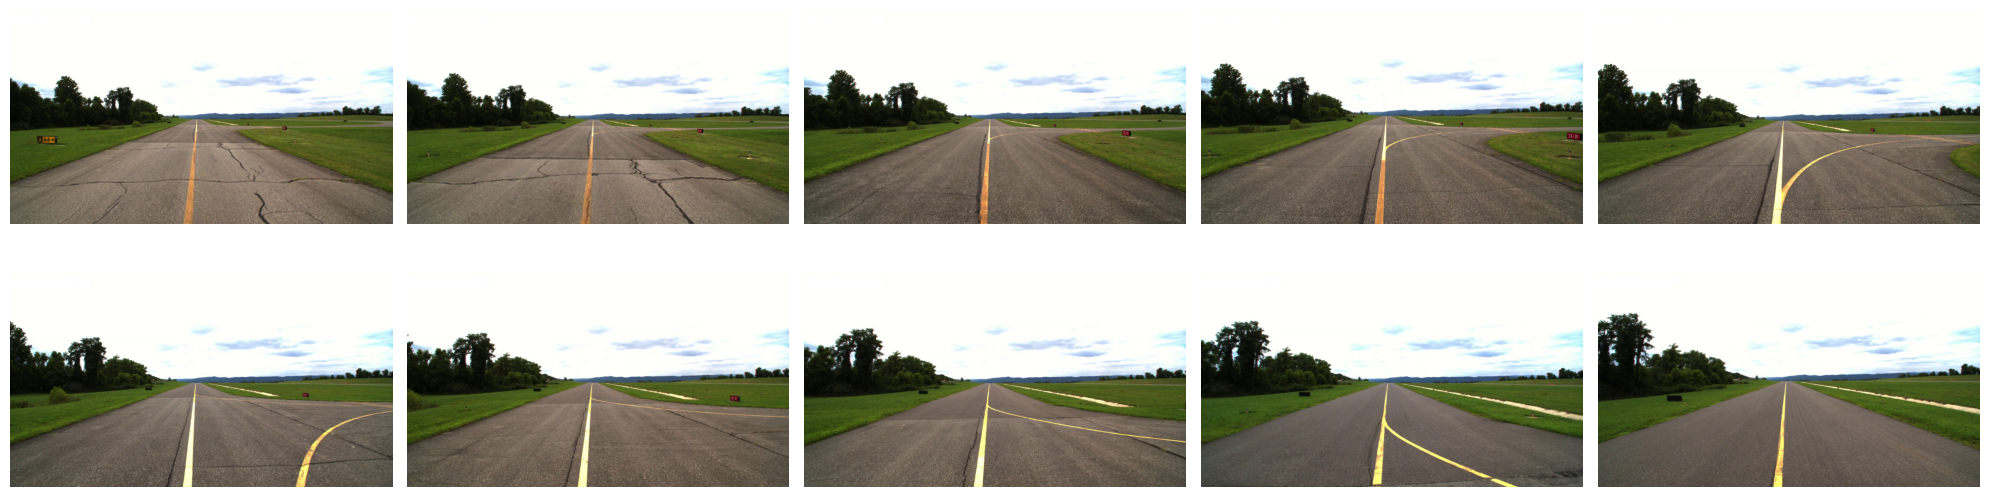

In [5]:
# Visualizer 
gnav.visualize_local_ims()

In [6]:
# Keep only points near the 10 test cameras (R in COLMAP units - tune by eye)
R_keep = 10.0
C = np.array([gnav.images_c[i].projection_center() for i in gnav.im_ids])
d = np.min(np.linalg.norm(gnav.scene_pts[:, None] - C[None], axis=2), axis=1)
near_idx = np.where(d < R_keep)[0]

# # RANSAC plane on the trimmed cloud, then map back to full scene_pts indices
# pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(gnav.scene_pts[near_idx]))
# plane, inl = pcd.segment_plane(distance_threshold=0.001, ransac_n=3, num_iterations=1000)
# pts_gnd_idx = near_idx[inl]
# print(len(near_idx), 'near pts,', len(pts_gnd_idx), 'ground pts')

# # Downsample ground pts (grav_SVD builds an N x N matrix - 16k pts is ~2 GB)
# np.random.seed(17)
# pts_gnd_idx = np.random.choice(pts_gnd_idx, 2000, replace=False)


# # Save April ground plane indices (into April scene_pts) and attach to class
# np.save('../datasets/KBCB_params/ground_pts_idxs_april.npy', pts_gnd_idx)
# gnav.pts_gnd_idx = pts_gnd_idx

pts_gnd_idx = np.load('../datasets/KBCB_params/ground_pts_idxs_april.npy')
gnav.pts_gnd_idx = pts_gnd_idx

In [7]:
# Using pre_calculated ground plane points - read explanation below 
# pts_gnd_idx = np.load('../datasets/KBCB_params/ground_pts_idxs.npy')
# gnav.pts_gnd_idx = pts_gnd_idx
# Run the ground plane extractor for visualization purposes 
# pts_gnd_idx_test = gnav.get_gnd_pts() 
# Visualize ground plane points 
# gnav.visualize_ground_pts(pts_gnd_idx) # UNCOMMENT for visualizations 

In [8]:
# # Visualize trimmed cloud (near_idx) with ground points in red
# vis = o3d.visualization.Visualizer()
# vis.create_window(window_name='Trimmed cloud + GROUND pts')

# # Near-camera cloud in its COLMAP colors
# near_cloud = o3d.geometry.PointCloud()
# near_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[near_idx])
# near_cloud.colors = o3d.utility.Vector3dVector(gnav.scene_rgb[near_idx])

# # Ground points in red
# gnd_cloud = o3d.geometry.PointCloud()
# gnd_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[pts_gnd_idx])
# gnd_cloud.paint_uniform_color([1.0, 0, 0])

# vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=1))
# vis.add_geometry(near_cloud)
# vis.add_geometry(gnd_cloud)
# vis.run()
# vis.destroy_window()


In [9]:
# Gather reference frame
tform_ref_frame = gnav.set_ref_frame() 
tform_ref_frame_pts = gnav.inv_homog_transform(tform_ref_frame)
gnav.tform_ref_frame_pts = tform_ref_frame_pts
print("\nReference frame transformation\n", tform_ref_frame_pts)

# Transform all points to the new coordinate system - for visual check 
tform_ref_frame_inv = gnav.inv_homog_transform(tform_ref_frame)
origin_ref, scene_pts_ref, scene_vec_ref = gnav.unit_vec_tform(gnav.scene_pts, gnav.origin_w, tform_ref_frame_inv)
gnav.scene_pts_ref = scene_pts_ref

Gravity vector 
 [-2.73274447e-02  9.99626473e-01 -3.53003698e-04]

Height h_0 =  0.1034266696436289

Reference frame transformation
 [[-9.98606130e-01 -2.72835956e-02  4.51818852e-02 -1.00931292e-01]
 [ 4.51553773e-02  1.58721713e-03  9.98978715e-01 -4.85095927e+00]
 [-2.73274447e-02  9.99626473e-01 -3.53003698e-04  8.96550857e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [10]:
# Height of each test camera above the ground plane (COLMAP units)
C = np.array([gnav.images_c[i].projection_center() for i in gnav.im_ids])
print((gnav.pts_gnd.mean(0) - C) @ gnav.grav_vec)



[0.10268075 0.10286519 0.10257522 0.10245267 0.10287438 0.10318866
 0.10262869 0.10297787 0.10301063 0.10113648]


In [11]:
# # Trimmed cloud + ground pts (red) + gravity vector (green) from ground centroid
# vis = o3d.visualization.Visualizer()
# vis.create_window(window_name='Trimmed cloud + GROUND pts + GRAVITY')

# near_cloud = o3d.geometry.PointCloud()
# near_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[near_idx])
# near_cloud.colors = o3d.utility.Vector3dVector(gnav.scene_rgb[near_idx])

# gnd_cloud = o3d.geometry.PointCloud()
# gnd_cloud.points = o3d.utility.Vector3dVector(gnav.pts_gnd)
# gnd_cloud.paint_uniform_color([1.0, 0, 0])

# # Gravity arrow (length 2 COLMAP units - hardcoded for April scale)
# start = gnav.pts_gnd.mean(0)
# grav_line = o3d.geometry.LineSet()
# grav_line.points = o3d.utility.Vector3dVector([start, start + 2.0 * gnav.grav_vec])
# grav_line.lines = o3d.utility.Vector2iVector([[0, 1]])
# grav_line.colors = o3d.utility.Vector3dVector([[0, 1, 0]])

# vis.add_geometry(near_cloud)
# vis.add_geometry(gnd_cloud)
# vis.add_geometry(grav_line)
# vis.run()
# vis.destroy_window()


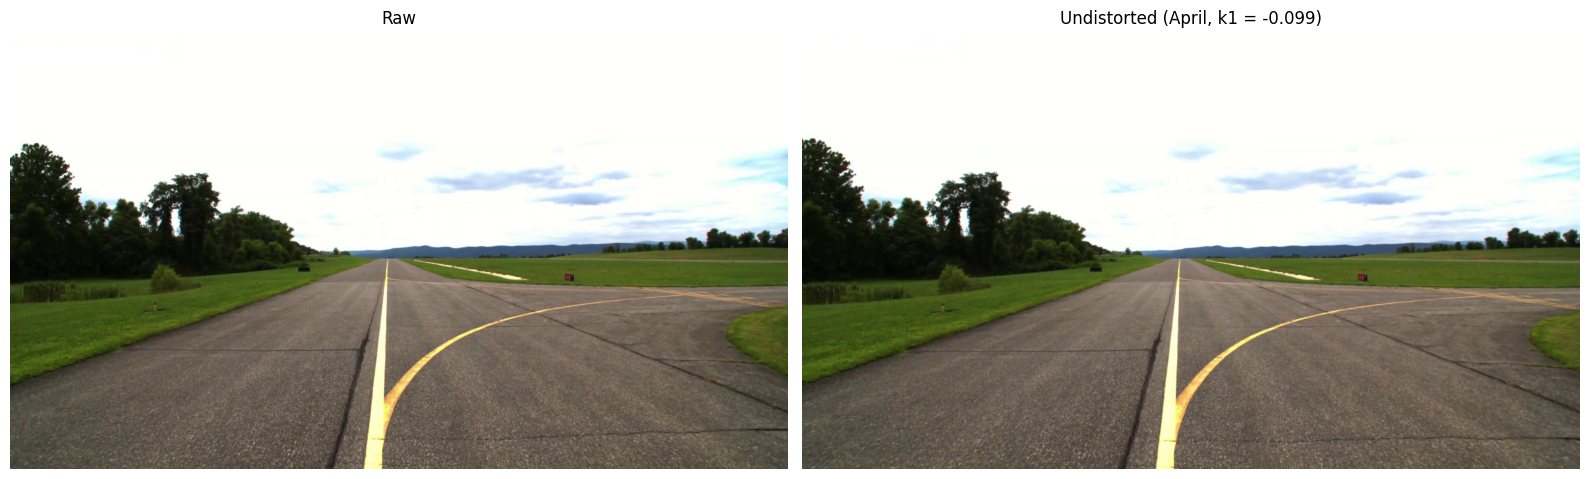

In [12]:
# Side by side: raw vs undistorted (April K, dist) - visualization only
# cv2.undistort resamples the whole image; unit_vec_c only corrects pixel coords (no resampling)
im_ind = 4
raw = gnav.images_dict[im_ind]
und = cv2.undistort(raw, gnav.K, gnav.dist)   # same K out -> same size, corners pushed off-frame

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for ax, im, name in zip(axs, [raw, und], ['Raw', f'Undistorted (April, k1 = {gnav.dist[0]:.3f})']):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(name); ax.axis('off')
plt.tight_layout()
plt.show()


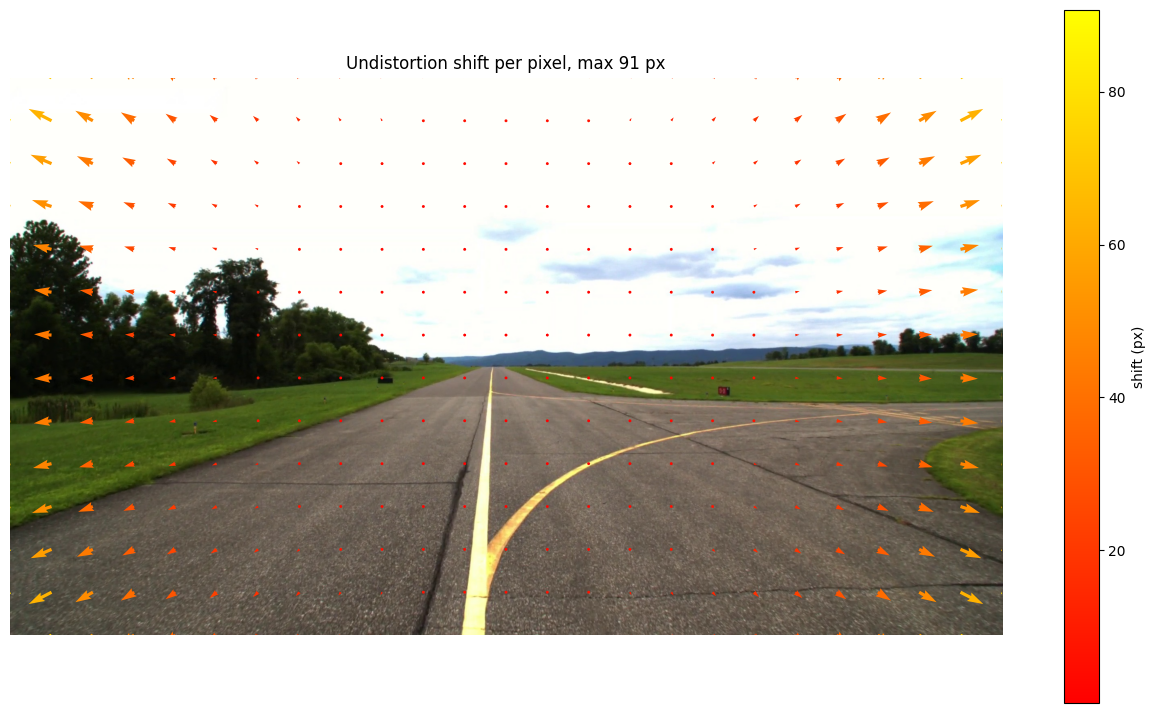

In [13]:
# Undistortion displacement field (April K, dist) on raw image - arrows at true pixel scale
im_ind = 4
raw = gnav.images_dict[im_ind]
H, W = raw.shape[:2]

# Grid of raw pixel locations
gu, gv = np.meshgrid(np.linspace(0, W-1, 25), np.linspace(0, H-1, 14))
px = np.stack((gu.ravel(), gv.ravel()), axis=1).reshape(-1,1,2)

# Undistorted pixel location (normalized coords back to pixels with the same K)
crit = (cv2.TERM_CRITERIA_COUNT | cv2.TERM_CRITERIA_EPS, 50, 1e-9)
und = cv2.undistortPoints(px, gnav.K, gnav.dist, P=gnav.K).reshape(-1,2)
d = und - px.reshape(-1,2)
mag = np.linalg.norm(d, axis=1)

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB))
q = plt.quiver(px[:,0,0], px[:,0,1], d[:,0], d[:,1], mag, angles='xy', scale_units='xy', scale=1, cmap='autumn')
plt.colorbar(q, label='shift (px)')
plt.title(f'Undistortion shift per pixel, max {mag.max():.0f} px')
plt.axis('off'); plt.show()


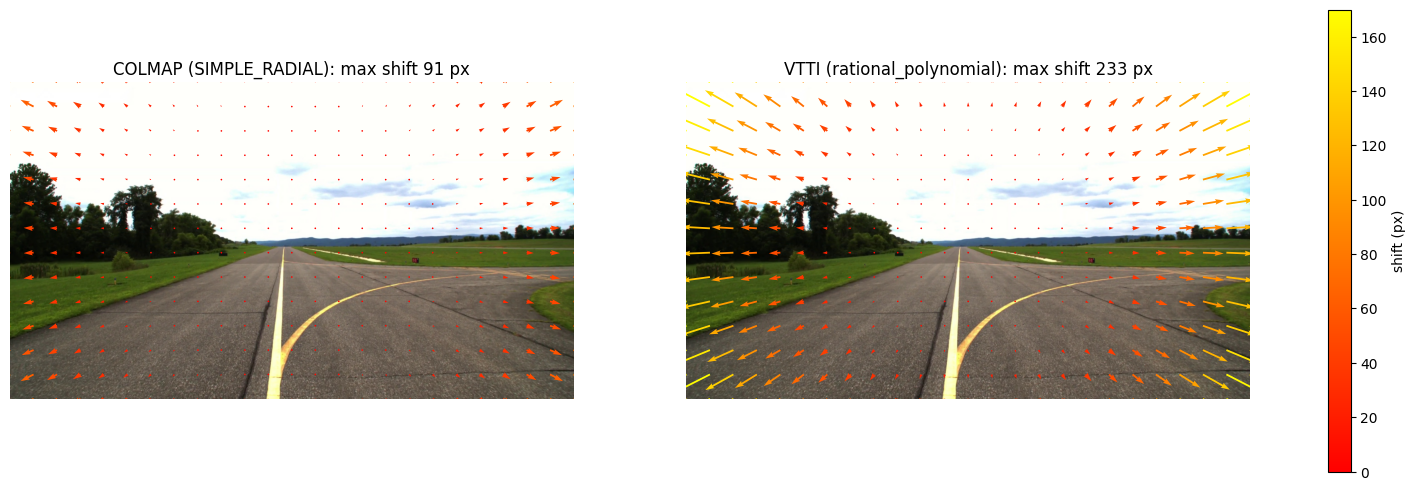

In [14]:
# VT intrinsics (ROS yaml) - visualization only, gnav still uses April
import yaml
with open('../datasets/KBCB_config/camera_forward.yaml') as fh:
    vt = yaml.safe_load(fh)
K_vt = np.array(vt['camera_matrix']['data']).reshape(3,3)
dist_vt = np.array(vt['distortion_coefficients']['data'])   # k1 k2 p1 p2 k3 k4 k5 k6

# Undistortion shift per grid pixel, April vs VT (same raw grid px)
fig, axs = plt.subplots(1, 2, figsize=(20, 6))
for ax, Kc, dc, name in zip(axs, [gnav.K, K_vt], [gnav.dist, dist_vt], ['COLMAP (SIMPLE_RADIAL)', 'VTTI (rational_polynomial)']):
    und = cv2.undistortPoints(px, Kc, dc, P=Kc).reshape(-1,2)
    d = und - px.reshape(-1,2)
    mag = np.linalg.norm(d, axis=1)
    ax.imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB))
    q = ax.quiver(px[:,0,0], px[:,0,1], d[:,0], d[:,1], mag, angles='xy', scale_units='xy', scale=1,
                  cmap='autumn', clim=(0, 170))   # shared color scale
    ax.set_title(f'{name}: max shift {mag.max():.0f} px'); ax.axis('off')
fig.colorbar(q, ax=axs, label='shift (px)')
plt.show()


[  75  800 2298  576] -> 1323648 pts per image


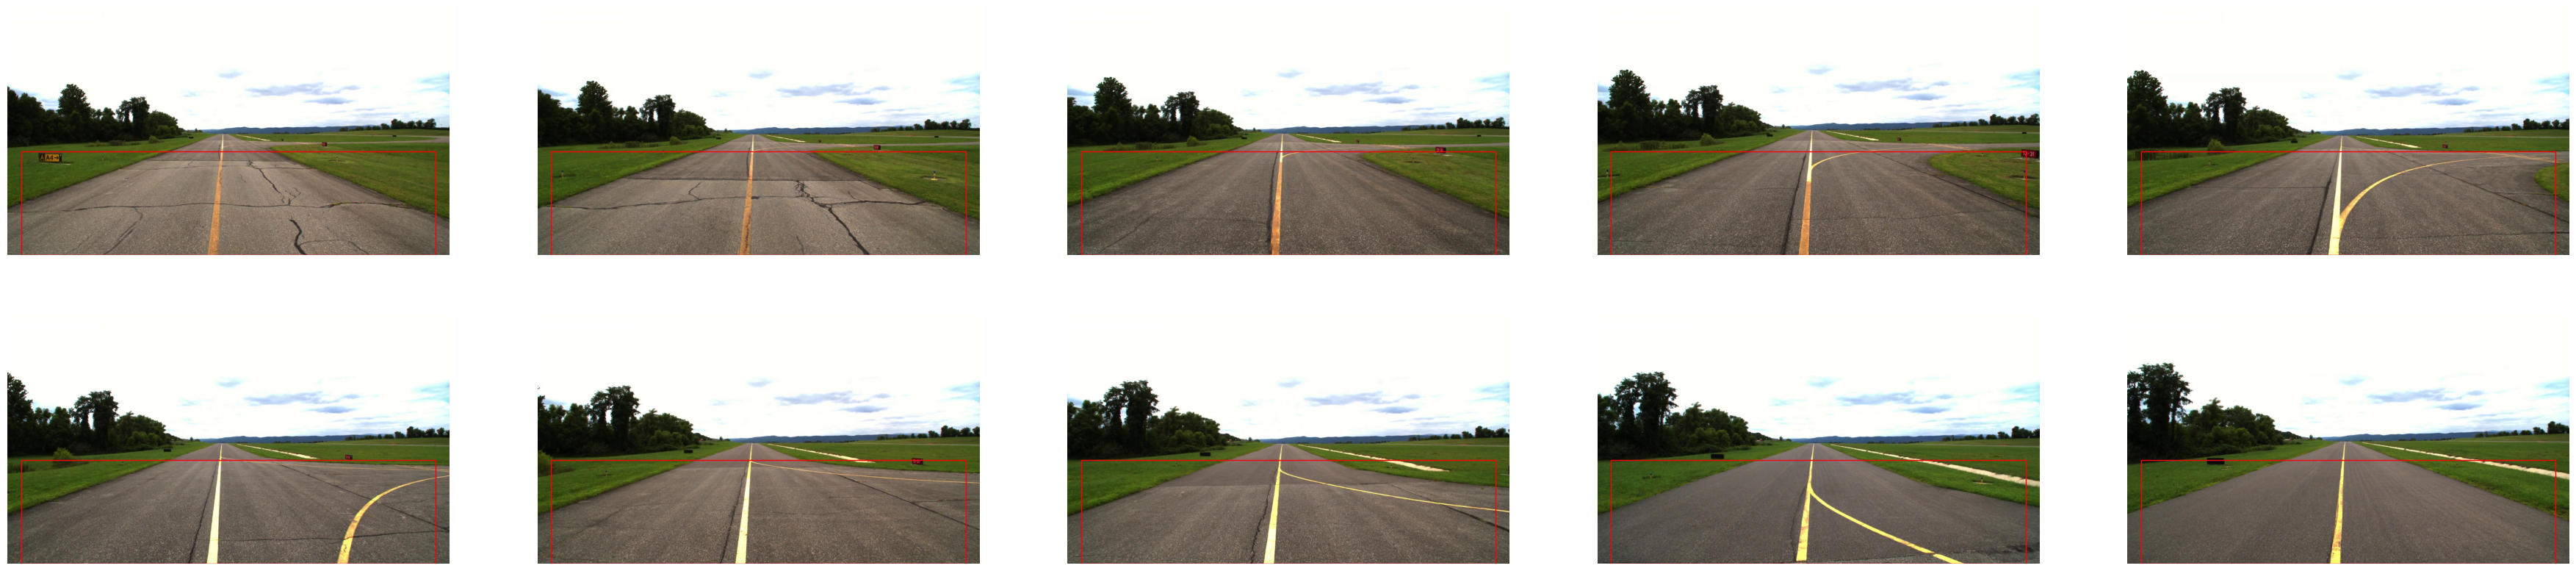

In [15]:
# Define ROI for image projection
# Per-image ROI (x, y, width, height) - lower image only, below horizon
# x0, y0 are a first guess (old 1600px ROI scaled by 2448/1600) - tune y0 by eye
x0, y0 = 75, 800 # CHANGED FROM 850
rois = np.array([(x0, y0, gnav.images_dict[i].shape[1] - 2*x0, gnav.images_dict[i].shape[0] - y0)
                 for i in range(gnav.im_num)])
print(rois[0], '->', rois[0, 2] * rois[0, 3], 'pts per image')

# Grab ROI pixels and draw boxes on all 10 frames
gnav.grab_image_pts_tot(rois)
gnav.plot_gnd_pts()


In [16]:
# ROI PROJECTION FUNCTION 

def project_roi(gnav, rois, d_pitch=0.0):
    """
    Grab ROI pixels and project onto the ground plane in the ref frame 
    Input: rois (num_ims x 4), each row (x, y, width, height)
           d_pitch: pitch perturbation (deg) about camera x-axis, applied to ALL images
                    + = optical axis tips up (COLMAP cam: y down, z forward)
    """
    gnav.grab_image_pts_tot(np.asarray(rois))

    # Pitch perturbation in camera frame (rotation about cam x, no translation)
    c, s = np.cos(np.deg2rad(d_pitch)), np.sin(np.deg2rad(d_pitch))
    T_pitch = np.array([[1, 0, 0, 0],
                        [0, c, -s, 0],
                        [0, s, c, 0],
                        [0, 0, 0, 1]])

    for i in range(gnav.im_num):
        # Unit vectors in camera coords
        pts_vec_c, pts_rgb_gnd = gnav.unit_vec_c(i)
        gnav.im_mosaic[i] = {'rgbc': pts_rgb_gnd}

        # Camera to world transform, with pitch perturbation
        homog_w2c, homog_c2w = gnav.get_pose_id(gnav.im_ids[i], i)
        homog_c2w = homog_c2w @ T_pitch

        # Transform to world coords and intersect with ground plane
        origin_c, pts_loc_w, pts_vec_w = gnav.unit_vec_tform(pts_vec_c, gnav.origin_w, homog_c2w)
        ranges, new_pts_w = gnav.pt_range(pts_vec_w, homog_c2w, origin_c, i)

        # Transfer points to reference frame
        __, new_pts_r, pts_vec_r = gnav.unit_vec_tform(new_pts_w, gnav.origin_w, gnav.tform_ref_frame_pts)

        # Store points and grayscale colors
        gnav.im_mosaic[i]['pts'] = new_pts_r
        gnav.im_mosaic[i]['color_g'] = gnav.conv_to_gray(gnav.im_mosaic[i]['rgbc'], i)

        # Image row of each point (same flattening order as pts) - for resolution check by row band
        gnav.im_mosaic[i]['rows'] = gnav.im_pts_2d[i]['pts'][..., 1].ravel()

        # Range check - r <= 0 means ray is at/above horizon
        r = gnav.im_pts_2d[i]['r']
        print(f"Image {i}: {r.size} pts, range min/max = {r.min():.3f}/{r.max():.3f}, "
              f"max/min = {r.max()/r.min():.1f}, r <= 0: {(r <= 0).sum()}")

## PROJECT ROIS

In [17]:
project_roi(gnav, rois)

Image 0: 1323648 pts, range min/max = 0.304/2.585, max/min = 8.5, r <= 0: 0
Image 1: 1323648 pts, range min/max = 0.305/2.706, max/min = 8.9, r <= 0: 0
Image 2: 1323648 pts, range min/max = 0.302/2.467, max/min = 8.2, r <= 0: 0
Image 3: 1323648 pts, range min/max = 0.294/2.057, max/min = 7.0, r <= 0: 0
Image 4: 1323648 pts, range min/max = 0.308/2.719, max/min = 8.8, r <= 0: 0
Image 5: 1323648 pts, range min/max = 0.306/2.651, max/min = 8.7, r <= 0: 0
Image 6: 1323648 pts, range min/max = 0.304/2.526, max/min = 8.3, r <= 0: 0
Image 7: 1323648 pts, range min/max = 0.307/2.686, max/min = 8.8, r <= 0: 0
Image 8: 1323648 pts, range min/max = 0.306/2.817, max/min = 9.2, r <= 0: 0
Image 9: 1323648 pts, range min/max = 0.296/2.091, max/min = 7.1, r <= 0: 0


In [18]:
# All 10 projected frames in ref frame - grayscale, every 4th pt for display speed
vis = o3d.visualization.Visualizer()
vis.create_window(window_name='Projected ROIs (April) - ref frame')
# for i in range(gnav.im_num):
for i in ([6]):
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['pts'][::4])
    cloud.colors = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['color_g'][::4])
    vis.add_geometry(cloud)
# vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=1))
vis.run()
vis.destroy_window()


In [19]:
# Manual placement on satellite: ONE (scale, yaw, tx, ty) shared by all 10 frames
scale, yaw_deg, tx, ty = 100, 126, -85, -38   # tune by eye, re-run [95, 126, -82, -35] IMAGE 4 [103, 126, -100, -48]
ind_params_april = np.tile([scale, np.deg2rad(yaw_deg), tx, ty], (gnav.im_num, 1))
gnav.implement_guess_ind(ind_params_april)

# Overlay: projected frames (orange tint) on satellite (gray)
vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f'April placement: scale {scale}, yaw {yaw_deg} deg, t ({tx}, {ty})')

# Origin 
origin_axis = o3d.geometry.TriangleMesh.create_coordinate_frame(size=1)

sat_cloud = o3d.geometry.PointCloud()
sat_cloud.points = o3d.utility.Vector3dVector(gnav.ref_pts)
sat_cloud.colors = o3d.utility.Vector3dVector(gnav.ref_rgb)
vis.add_geometry(sat_cloud)

# for i in range(gnav.im_num):
for i in ([0,2,4,6,8]):
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(gnav.im_pts_best_guess[i]['pts'][::4])
    cloud.colors = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['color_g'][::4] * np.array([1.0, 0.55, 0.1]))
    vis.add_geometry(cloud)



# vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=50))


# # # Zoom out the initial view (larger = farther; Open3D caps it at 2.0)
# ctr = vis.get_view_control()
# ctr.set_zoom(2.0)
# ctr.change_field_of_view(step=30)   # widen toward Open3D's 90° max (default 60°)
vis.run()
vis.destroy_window()

Image 0: SSD at (0,0) = 0.5286, min = 0.5181 at shift (+5, +3)
Image 1: SSD at (0,0) = 0.7280, min = 0.7204 at shift (-4, -3)
Image 2: SSD at (0,0) = 0.8473, min = 0.7542 at shift (-5, -4)
Image 3: SSD at (0,0) = 0.6481, min = 0.6080 at shift (-4, -3)
Image 4: SSD at (0,0) = 0.6433, min = 0.6433 at shift (+0, +0)
Image 5: SSD at (0,0) = 0.8174, min = 0.7334 at shift (+4, +3)
Image 6: SSD at (0,0) = 1.1307, min = 1.0894 at shift (+5, +4)
Image 7: SSD at (0,0) = 1.1647, min = 0.9786 at shift (+5, -5)
Image 8: SSD at (0,0) = 1.1363, min = 0.9629 at shift (+5, -5)
Image 9: SSD at (0,0) = 1.0912, min = 1.0371 at shift (+0, +1)


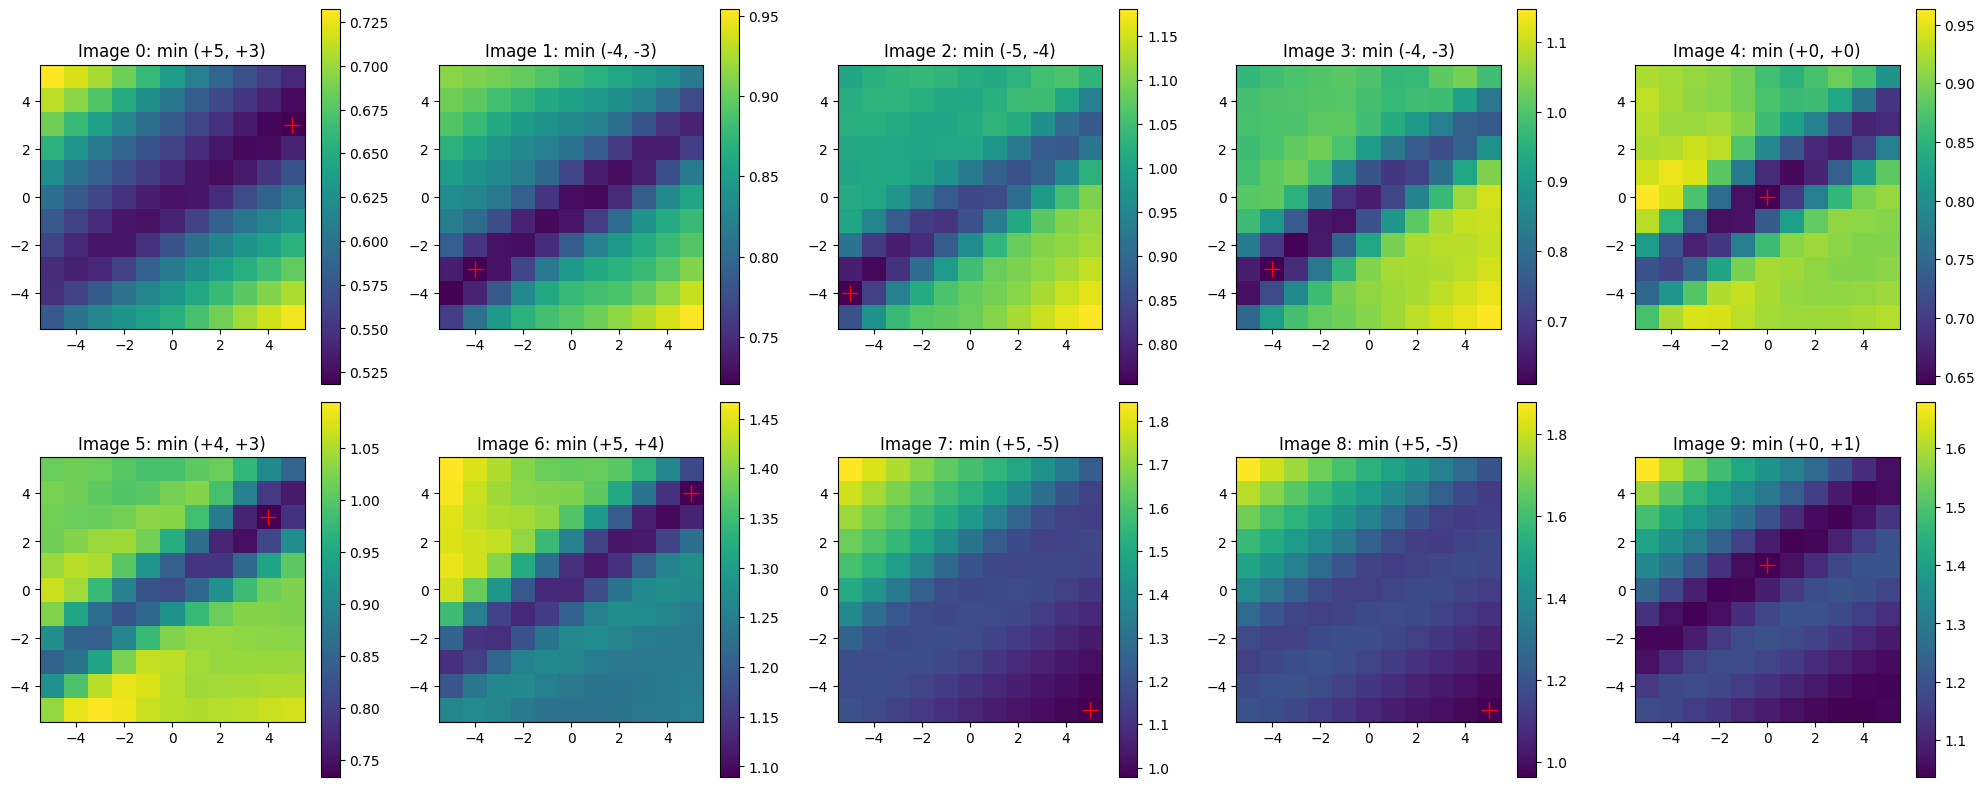

In [35]:
# Per-frame SSD around the shared April placement - offset of the minimum = error measure
n = 5
ssd_april = {}
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in zip(range(gnav.im_num), axs.ravel()):
    ssds = ssd_april[i] = gnav.ssd_norm(i, n)
    ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
    print(f"Image {i}: SSD at (0,0) = {ssds[n, n]:.4f}, min = {ssds.min():.4f} at shift ({ix-n:+d}, {iy-n:+d})")
    im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(f'Image {i}: min ({ix-n:+d}, {iy-n:+d})')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


# VTTI INTRINSICS

Doing a quick swap for colmap intrinsics vs VTTI intrinsics
#### NOTE: gnav now holds VT intrinsics - to re-run April cells above, first set gnav.K, gnav.dist = K, dist


In [21]:
# Quick swap: VT intrinsics on April poses (poses NOT re-solved - pitch bias absorbed by d_pitch sweep only)
gnav.K, gnav.dist = K_vt, dist_vt
project_roi(gnav, rois)


Image 0: 1323648 pts, range min/max = 0.260/2.375, max/min = 9.1, r <= 0: 0
Image 1: 1323648 pts, range min/max = 0.261/2.484, max/min = 9.5, r <= 0: 0
Image 2: 1323648 pts, range min/max = 0.259/2.273, max/min = 8.8, r <= 0: 0
Image 3: 1323648 pts, range min/max = 0.253/1.940, max/min = 7.7, r <= 0: 0
Image 4: 1323648 pts, range min/max = 0.263/2.457, max/min = 9.3, r <= 0: 0
Image 5: 1323648 pts, range min/max = 0.262/2.423, max/min = 9.2, r <= 0: 0
Image 6: 1323648 pts, range min/max = 0.260/2.313, max/min = 8.9, r <= 0: 0
Image 7: 1323648 pts, range min/max = 0.262/2.445, max/min = 9.3, r <= 0: 0
Image 8: 1323648 pts, range min/max = 0.261/2.587, max/min = 9.9, r <= 0: 0
Image 9: 1323648 pts, range min/max = 0.254/1.926, max/min = 7.6, r <= 0: 0


In [22]:
# All 10 projected frames in ref frame - grayscale, every 4th pt for display speed
vis = o3d.visualization.Visualizer()
vis.create_window(window_name='Projected ROIs (VT) - ref frame')
# for i in range(gnav.im_num):
for i in ([6]):
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['pts'][::4])
    cloud.colors = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['color_g'][::4])
    vis.add_geometry(cloud)
# vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=1))
vis.run()
vis.destroy_window()


In [36]:
# Manual placement on satellite: ONE (scale, yaw, tx, ty) shared by all 10 frames
scale, yaw_deg, tx, ty = 105, 126, -116, -60   # tune by eye, re-run, [95, 126, -97, -47] # FRAME 4 [108, 126, -120, -63], all frames[105, 126, -101, -50]
ind_params_vt = np.tile([scale, np.deg2rad(yaw_deg), tx, ty], (gnav.im_num, 1))
gnav.implement_guess_ind(ind_params_vt)

# Overlay: projected frames (orange tint) on satellite (gray)
vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f'VT placement: scale {scale}, yaw {yaw_deg} deg, t ({tx}, {ty})')

# Origin 
origin_axis = o3d.geometry.TriangleMesh.create_coordinate_frame(size=1)

sat_cloud = o3d.geometry.PointCloud()
sat_cloud.points = o3d.utility.Vector3dVector(gnav.ref_pts)
sat_cloud.colors = o3d.utility.Vector3dVector(gnav.ref_rgb)
vis.add_geometry(sat_cloud)

# for i in range(gnav.im_num):
for i in ([4]):
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(gnav.im_pts_best_guess[i]['pts'][::4])
    cloud.colors = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['color_g'][::4] * np.array([1.0, 0.55, 0.1]))
    vis.add_geometry(cloud)

# vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=10))
vis.run()
vis.destroy_window()

Image 0: SSD at (0,0) = 0.5286, min = 0.5181 at shift (+5, +3)
Image 1: SSD at (0,0) = 0.7280, min = 0.7204 at shift (-4, -3)
Image 2: SSD at (0,0) = 0.8473, min = 0.7542 at shift (-5, -4)
Image 3: SSD at (0,0) = 0.6481, min = 0.6080 at shift (-4, -3)
Image 4: SSD at (0,0) = 0.6433, min = 0.6433 at shift (+0, +0)
Image 5: SSD at (0,0) = 0.8174, min = 0.7334 at shift (+4, +3)
Image 6: SSD at (0,0) = 1.1307, min = 1.0894 at shift (+5, +4)
Image 7: SSD at (0,0) = 1.1647, min = 0.9786 at shift (+5, -5)
Image 8: SSD at (0,0) = 1.1363, min = 0.9629 at shift (+5, -5)
Image 9: SSD at (0,0) = 1.0912, min = 1.0371 at shift (+0, +1)


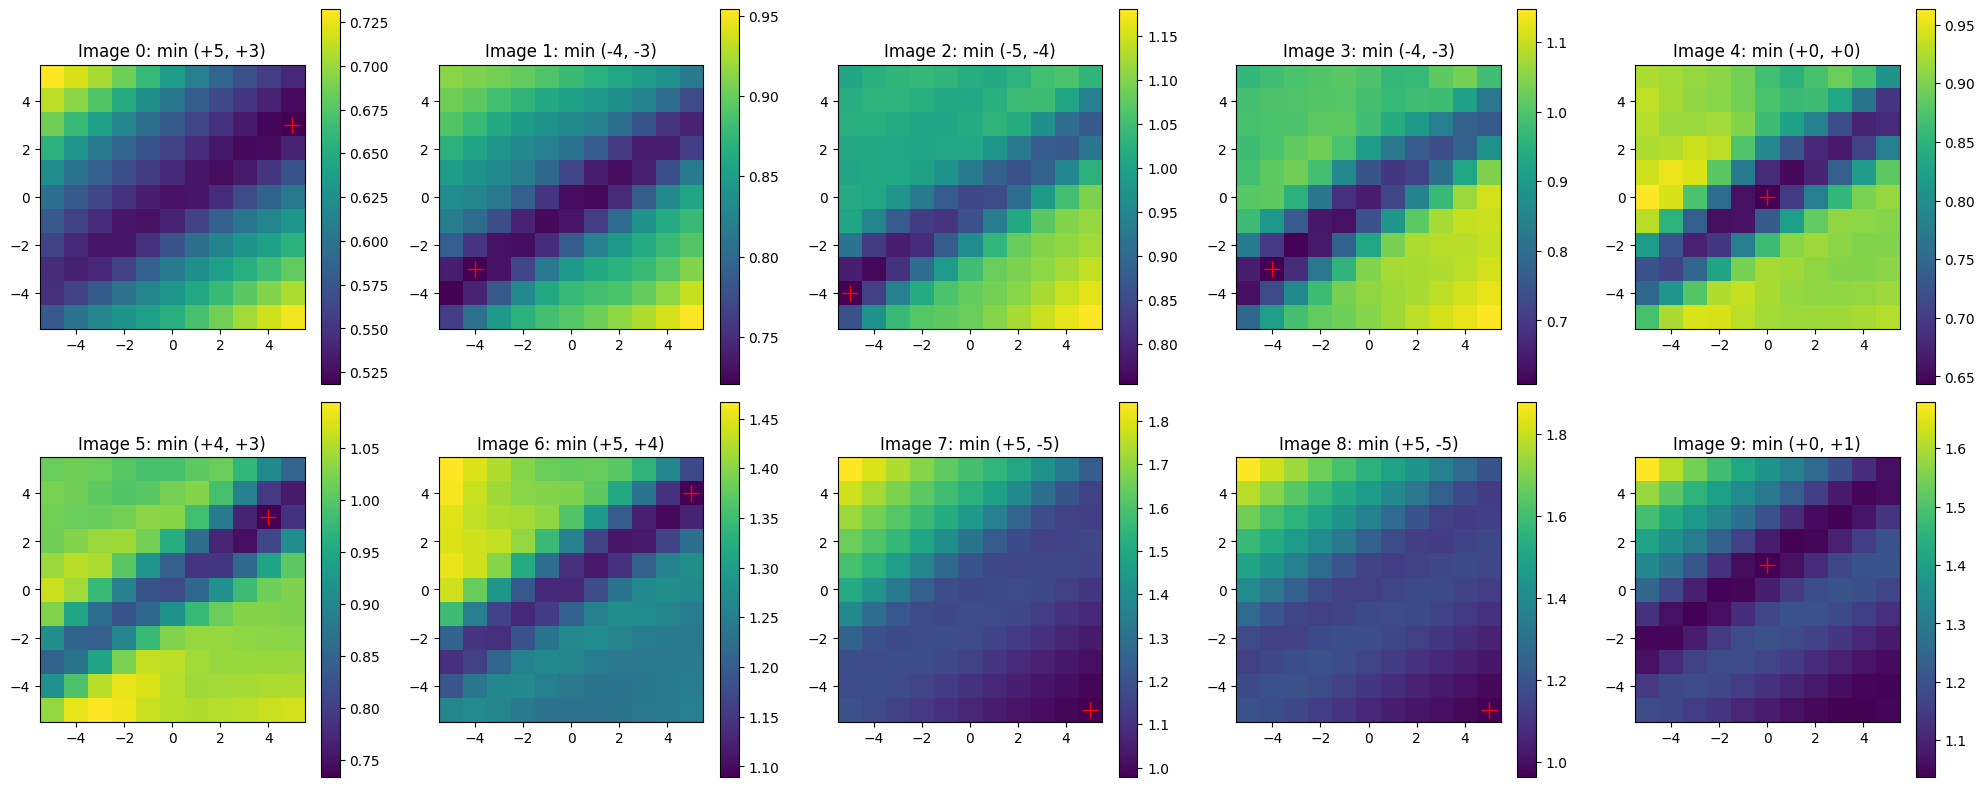

In [37]:
# Per-frame SSD around the shared VT placement - offset of the minimum = error measure
n = 5
ssd_vt = {}
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in zip(range(gnav.im_num), axs.ravel()):
    ssds = ssd_vt[i] = gnav.ssd_norm(i, n)
    ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
    print(f"Image {i}: SSD at (0,0) = {ssds[n, n]:.4f}, min = {ssds.min():.4f} at shift ({ix-n:+d}, {iy-n:+d})")
    im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(f'Image {i}: min ({ix-n:+d}, {iy-n:+d})')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


In [38]:
import plotly.graph_objects as go

# SSD surface plot (plotly) - image 4, from the per-frame SSD above (same style as calibration_test)
im_ind = 4
ssds = ssd_april[im_ind]   # dict name copied from calib_raw - holds VT-fixed SSDs here
x = np.linspace(-n, n, 2*n + 1)
Y, X = np.meshgrid(x, x)  # ssds indexed [shiftx + n, shifty + n]

idrow, idcol = np.unravel_index(np.argmin(ssds), ssds.shape)
fig = go.Figure()
fig.add_surface(x=X, y=Y, z=ssds, colorscale='Viridis', colorbar=dict(title='SSD'), name='SSD Surface')
fig.add_trace(go.Scatter3d(x=[idrow - n], y=[idcol - n], z=[ssds[idrow, idcol]],
                           mode='markers', marker=dict(size=6, color='red'), name='Min SSD'))
fig.add_trace(go.Scatter3d(x=[0], y=[0], z=[ssds[n, n]],
                           mode='markers', marker=dict(size=6, color='black'), name='Placement (0,0)'))
fig.update_layout(
    title=f'Normalized SSD: image {im_ind} (VT-fixed)',
    scene=dict(xaxis=dict(title='X Shift (pixels)', range=[-n, n], dtick=1),
               yaxis=dict(title='Y Shift (pixels)', range=[-n, n], dtick=1),
               zaxis=dict(title='SSD'),
               camera=dict(eye=dict(x=1.5, y=1.5, z=1.2)),
               aspectmode='cube'),
    width=900, height=800)
fig.show()